<a href="https://colab.research.google.com/github/Fen-Pang/Capstone-Market-Analysis/blob/main/Market_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Part 1: Descriptive Analysis on Sales




## 1. Import libraries and data files

In [2]:
## Import customer and purchase datasets from GitHub into Google Colab
import pandas as pd
customer = pd.read_csv('https://raw.githubusercontent.com/Fen-Pang/Capstone-Market-Analysis/main/customer.csv')
purchase = pd.read_csv('https://raw.githubusercontent.com/Fen-Pang/Capstone-Market-Analysis/main/purchase.csv')
customer.head()

,customer_id,first_name,last_name,gender,age,country,income
0,CS00001,Isadora,Porto,Female,19,Brazil,117196
1,CS00002,Hugo,Carreño,Male,33,Chile,49256
2,CS00003,René,Olivera,Male,65,Mexico,33434
3,CS00004,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,CS00005,Leonardo,Monteiro,Male,19,Brazil,32280


## 2. Exploratory Data Analysis (EDA)

In [3]:
# 2.1: Check dataset on number of rows and columns
print(customer.shape)
print(purchase.shape)

# Outcome: 1,001 customers and 50,000 purchases

(1001, 7)
(50000, 11)


In [4]:
# 2.2: Check dataset on column names, data types and missing values
customer.info()
purchase.info()

# Outcome: Order date and shipping date are stored as object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  1001 non-null   object
 1   first_name   1001 non-null   object
 2   last_name    1001 non-null   object
 3   gender       1001 non-null   object
 4   age          1001 non-null   int64 
 5   country      1001 non-null   object
 6   income       1001 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 54.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50000 non-null  object 
 1   customer_id    50000 non-null  object 
 2   product_name   50000 non-null  object 
 3   description    50000 non-null  object 
 4   price          50000 non-null  float64
 5   discount       50000 non-null  float64
 6   tax     

In [5]:
# 2.3: Check dataset for missing values in both datasets
print(customer.isnull().sum())
print(purchase.isnull().sum())

# Outcome: No missing values

customer_id    0
first_name     0
last_name      0
gender         0
age            0
country        0
income         0
dtype: int64
order_id         0
customer_id      0
product_name     0
description      0
price            0
discount         0
tax              0
order_date       0
quantity         0
shipping_cost    0
shipping_date    0
dtype: int64


In [6]:
#2.4: Check dataset for duplicate rows in both datasets
print(customer.duplicated().sum())
print(purchase.duplicated().sum())

# Outcome: No duplicate

0
0


In [7]:
#2.5:  Check basic statistics of both datasets
display(customer.describe())
display(purchase.describe())

# Outcome: Average customer age is 41, income is $84,629 and average purchase price is $1,275.93

,age,income
count,1001.000000,1001.000000
mean,41.337662,84628.809191
std,13.732657,37498.010417
min,18.000000,20205.000000
25%,29.000000,52092.000000
50%,41.000000,83654.000000
75%,53.000000,116549.000000
max,65.000000,149980.000000


,price,discount,tax,quantity,shipping_cost
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1275.926873,0.249116,0.050081,5.497560,27.509281
std,1315.400328,0.144386,0.029159,2.862313,12.952128
min,20.020000,0.000000,0.000000,1.000000,5.000000
25%,219.675000,0.120000,0.030000,3.000000,16.360000
50%,834.395000,0.250000,0.050000,5.000000,27.580000
75%,1837.397500,0.370000,0.080000,8.000000,38.670000
max,4999.950000,0.500000,0.100000,10.000000,50.000000


## 3. Data Cleansing & Preparation

In [8]:
# 3.1 Convert date columns to datetime
purchase['order_date'] = pd.to_datetime(purchase['order_date'], format='%d/%m/%Y')
purchase['shipping_date'] = pd.to_datetime(purchase['shipping_date'], format='%d/%m/%Y')

# Check updated data types
purchase.info()

# Outcome: Both date columns converted to datetime

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       50000 non-null  object        
 1   customer_id    50000 non-null  object        
 2   product_name   50000 non-null  object        
 3   description    50000 non-null  object        
 4   price          50000 non-null  float64       
 5   discount       50000 non-null  float64       
 6   tax            50000 non-null  float64       
 7   order_date     50000 non-null  datetime64[ns]
 8   quantity       50000 non-null  int64         
 9   shipping_cost  50000 non-null  float64       
 10  shipping_date  50000 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(4), int64(1), object(4)
memory usage: 4.2+ MB


In [9]:
# 3.2 Check data consistency
print(customer['gender'].unique())
print(customer['country'].unique())
print(purchase['product_name'].unique())

# Outcome: No obvious inconsistencies found in text values

['Female' 'Male']
['Brazil' 'Chile' 'Mexico' 'Colombia']
['Furniture' 'Dress' 'Shoes' 'Rugs' 'Virtual Reality Headset' 'Tablet'
 'Dining Set' 'Formal Shirt' 'Lighting' 'Skirt' 'TV' 'Camera'
 'Smart Watch' 'Appliance Set' 'Laptop' 'Kitchen Appliances' 'Headphones'
 'Wireless Speaker' 'Gaming Console' 'Curtains' 'Sports Shoes'
 'Activewear Set' 'Wall Art' 'Jacket' 'T-Shirt' 'Sweater' 'Home Decor'
 'Jeans' 'Smartphone' 'Bedding']


In [11]:
# 3.3 Check duplicate IDs
print(customer['customer_id'].is_unique)
print(purchase['order_id'].is_unique)

# Outcome: All customer IDs and order IDs are unique. No duplicate IDs

True
True


✅ Data Cleaning & Validation: Based on the checks, no missing values, duplicate records or obvious data inconsistencies were found. Date formats were corrected, so no further data cleaning was needed.

## 4. Sales Analysis

In [12]:
# 4.1 Calculate the actual sales amount after discount

purchase['sales'] = purchase['price'] * purchase['quantity'] * (1 - purchase['discount'])

purchase[['price', 'quantity', 'discount', 'sales']].head()

# Outcome: Sales amount after discount calculated for each purchase

,price,quantity,discount,sales
0,645.52,9,0.37,3660.0984
1,28.90,9,0.05,247.0950
2,3536.49,3,0.21,8381.4813
3,97.80,7,0.11,609.2940
4,1785.38,7,0.13,10872.9642


In [14]:
# 4.2 Calculate total sales revenue from all purchases after discounts

total_sales = purchase['sales'].sum()

print("Total Sales Revenue:", round(total_sales, 2))

# Outcome: Total sales revenue after discounts is $263,688,338.84

Total Sales Revenue: 263688338.84


In [16]:
# 4.3 Analyse monthly sales trends

purchase['month'] = purchase['order_date'].dt.to_period('M')

monthly_sales = purchase.groupby('month')['sales'].sum()

print(monthly_sales)

# Outcome: Sales fluctuated from Aug 2019 to Jan 2023, with most months generating around $6–7 million

month
2019-08    3.465169e+06
2019-09    5.795560e+06
2019-10    7.419917e+06
2019-11    6.042039e+06
2019-12    6.791918e+06
2020-01    7.180929e+06
2020-02    5.819276e+06
2020-03    7.117483e+06
2020-04    6.711225e+06
2020-05    7.187533e+06
2020-06    6.660013e+06
2020-07    6.587619e+06
2020-08    6.787696e+06
2020-09    6.411313e+06
2020-10    6.775231e+06
2020-11    6.162922e+06
2020-12    6.199566e+06
2021-01    6.414512e+06
2021-02    6.290633e+06
2021-03    6.431606e+06
2021-04    6.450787e+06
2021-05    6.121784e+06
2021-06    6.227124e+06
2021-07    6.652095e+06
2021-08    6.614010e+06
2021-09    6.428757e+06
2021-10    6.718969e+06
2021-11    6.354969e+06
2021-12    6.071222e+06
2022-01    6.464322e+06
2022-02    5.872112e+06
2022-03    6.266416e+06
2022-04    6.450582e+06
2022-05    7.307882e+06
2022-06    6.111676e+06
2022-07    6.386286e+06
2022-08    6.661843e+06
2022-09    6.262907e+06
2022-10    6.633499e+06
2022-11    6.681530e+06
2022-12    6.452515e+06
2023-01   

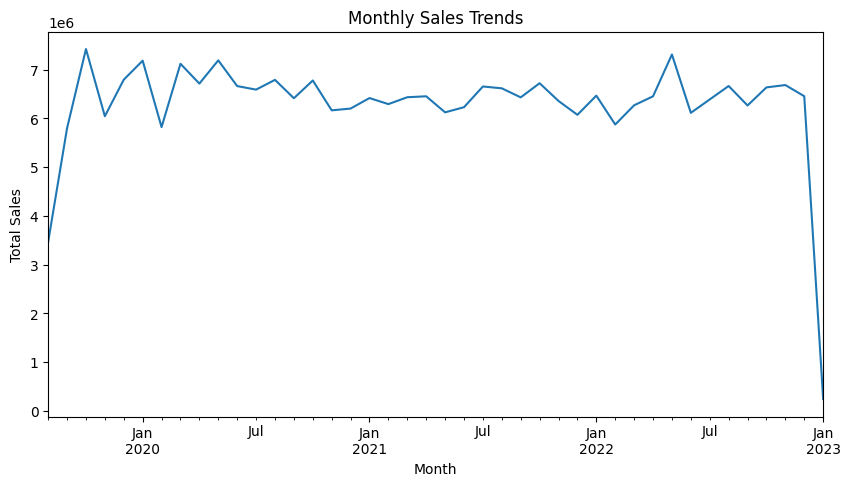

In [18]:
# 4.4 Visualise monthly sales trends

import matplotlib.pyplot as plt

monthly_sales.plot(kind='line', figsize=(10, 5))

plt.title('Monthly Sales Trends')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()

# Outcome: The line chart shows no clear upward or downward sales trend, except for a sharp drop in Jan 2023

## 5. Product Sales Analysis

In [22]:
# 5 Identify best-selling products and their contribution to overall sales

# Total sales by product
product_sales = purchase.groupby('product_name')['sales'].sum().sort_values(ascending=False)

# Percentage contribution to total sales
product_percentage = (product_sales / total_sales * 100).round(2)

# Total quantity sold by product
product_quantity = purchase.groupby('product_name')['quantity'].sum().sort_values(ascending=False)

print("Sales Revenue by Product:")
print(product_sales)

print("\nPercentage of Total Sales:")
print(product_percentage)

print("\nQuantity Sold by Product:")
print(product_quantity)

# Outcome: Curtains generated the highest revenue (7.06% of total sales), while sports shoes had the highest quantity sold (9,642 units)

Sales Revenue by Product:
product_name
Curtains                   1.862254e+07
Wall Art                   1.823360e+07
Lighting                   1.794835e+07
Furniture                  1.790821e+07
Kitchen Appliances         1.773733e+07
Rugs                       1.763230e+07
Dining Set                 1.760793e+07
Appliance Set              1.756617e+07
Home Decor                 1.723472e+07
Bedding                    1.682238e+07
Wireless Speaker           7.755158e+06
Camera                     7.709608e+06
Gaming Console             7.646230e+06
Tablet                     7.641781e+06
Headphones                 7.627380e+06
Smartphone                 7.548188e+06
Smart Watch                7.427628e+06
TV                         7.395262e+06
Laptop                     7.376470e+06
Virtual Reality Headset    7.283052e+06
Sports Shoes               1.156007e+06
Jacket                     1.155103e+06
Jeans                      1.129295e+06
Activewear Set             1.119410e+06
T

## 6. Customer Demographics and Spending Analysis

In [25]:
# 6.1 Check customer spending by gender

# Combine customer and purchase data
customer_sales = pd.merge(purchase, customer, on='customer_id')

# Total sales by gender
print(customer_sales.groupby('gender')['sales'].sum())

# Outcome: Male customers (approx $132.78 million) generated slightly higher sales revenue than female customers (approx $130.91 million)

gender
Female    1.309095e+08
Male      1.327789e+08
Name: sales, dtype: float64


In [26]:
# 6.2 Check average spending by customer age
print(customer_sales.groupby('age')['sales'].mean().round(2))

# Outcome: Customers aged 51 had the highest average spending per purchase

age
18    5159.57
19    4886.01
20    5828.61
21    4999.34
22    5323.22
23    4998.71
24    5353.94
25    5248.78
26    5446.48
27    5102.12
28    5512.04
29    5463.16
30    5113.10
31    5018.26
32    5010.52
33    5107.13
34    5645.38
35    5281.53
36    5137.02
37    5000.89
38    4655.69
39    5651.55
40    5281.82
41    4963.06
42    5158.12
43    5062.78
44    5527.58
45    5270.82
46    4957.91
47    5376.85
48    5220.99
49    5142.96
50    5203.82
51    5881.29
52    5577.18
53    5655.39
54    5296.35
55    5222.04
56    5379.18
57    5122.27
58    5390.81
59    5386.53
60    5161.82
61    5500.81
62    5286.36
63    5579.83
64    5159.30
65    5254.46
Name: sales, dtype: float64


In [27]:
# 6.3 Identify high-value customer by spending and purchase frequency

# Total spending and number of purchases by customer
customer_value = customer_sales.groupby('customer_id').agg({
    'sales': 'sum',
    'order_id': 'count'
})

# Top 10 customers by total spending
print(customer_value.sort_values('sales', ascending=False).head(10))

# Outcome: Customer CS00609 had the highest spending ($446,568.14) and all top 10 customers made 50 purchases each

                   sales  order_id
customer_id                       
CS00609      446568.1352        50
CS00810      421694.5730        50
CS00994      396479.2409        50
CS00336      395087.1170        50
CS00176      394940.5595        50
CS00147      394287.8403        50
CS00870      392959.3939        50
CS00777      392001.5605        50
CS00287      391829.7240        50
CS00543      390739.5949        50


## 7. Sales Analysis by Country

In [29]:
# 7. Compare total sales by country

country_sales = customer_sales.groupby('country')['sales'].sum()

print(country_sales.sort_values(ascending=False))

# Outcome: Highest sales is Colombia ($74.37 million) and lowest is Brazil ($60.79 million)

country
Colombia    7.436621e+07
Chile       6.680852e+07
Mexico      6.172365e+07
Brazil      6.078996e+07
Name: sales, dtype: float64


## 8. Export Prepared Datasets

In [30]:
# 8. Export prepared datasets

customer.to_csv('customer_cleaned.csv', index=False)
purchase.to_csv('purchase_cleaned.csv', index=False)

print("Datasets exported successfully!")

Datasets exported successfully!
